<a href="https://colab.research.google.com/github/Michruiz2710/skin-cancer-detection-APPR/blob/main/notebooks/03_entrenamiento_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 · Entrenamiento v3 — DenseNet201 Mejorado

**Proyecto APPR — Detección de Cáncer de Piel**

Mejoras sobre v2:

| # | Mejora | Razón |
|---|---|---|
| 1 | CrossEntropy + class_weights en Fase 1 (no Focal Loss) | Focal Loss ralentiza convergencia cuando el modelo es aleatorio |
| 2 | LR Fase 1: 1e-3 (antes 1e-4) | Acelera convergencia del clasificador con base congelada |
| 3 | Épocas Fase 1: 30 (antes 20) | Más tiempo para que el clasificador converja |
| 4 | Fine-tuning gradual: 50 capas → 100 capas | Evita destruir pesos aprendidos en Fase 1 |
| 5 | Augmentation ampliado: +RandomContrast +RandomTranslation | Dermoscopía tiene variación de iluminación y posición |
| 6 | Val pipeline con .cache() | Evita releer disco en cada época |


## 1 · Configuración del entorno

In [ ]:
import os
from google.colab import drive

!usr/bin/fusermount -u /content/drive 2>/dev/null || true
if os.path.exists('/content/drive') and os.listdir('/content/drive') == []:
    os.rmdir('/content/drive')

drive.mount('/content/drive', force_remount=True)
print('✅ Drive montado')

Mounted at /content/drive
✅ Drive montado


In [ ]:
!pip install -q datasets
print('✅ datasets instalado')

✅ datasets instalado


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.applications import DenseNet201
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping
from sklearn.utils import resample
print('TF:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TF: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2 · Rutas y configuración

In [ ]:
# ── RUTAS ─────────────────────────────────────────────────────────────────────
DRIVE_BASE = '/content/drive/MyDrive/skin-cancer-APPR'
MODELS_DIR = os.path.join(DRIVE_BASE, 'models')
DATA_DIR   = os.path.join(DRIVE_BASE, 'data')
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(DATA_DIR,   exist_ok=True)

# ── HIPERPARÁMETROS ───────────────────────────────────────────────────────────
IMG_SIZE         = 224
BATCH_SIZE       = 32
TARGET_PER_CLASS = 2000
NUM_CLASSES      = 7

# Fase 1: clasificador con base congelada
EPOCHS_PHASE1    = 30       # v3: 30 (era 20)
LR_PHASE1        = 1e-3     # v3: 1e-3 (era 1e-4) — más rápido con base congelada

# Fase 2a: fine-tuning últimas 50 capas
EPOCHS_PHASE2A   = 20
LR_PHASE2A       = 1e-5

# Fase 2b: fine-tuning últimas 100 capas (gradual)
EPOCHS_PHASE2B   = 20
LR_PHASE2B       = 5e-6

UNFREEZE_PHASE2A = 50
UNFREEZE_PHASE2B = 100
DROPOUT_RATE     = 0.5

CLASS_NAMES = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']

HF_TO_SHORT = {
    'melanocytic_Nevi':              'nv',
    'melanoma':                      'mel',
    'benign_keratosis-like_lesions': 'bkl',
    'basal_cell_carcinoma':          'bcc',
    'actinic_keratoses':             'akiec',
    'vascular_lesions':              'vasc',
    'dermatofibroma':                'df',
}
CLASS_INDEX = {name: i for i, name in enumerate(CLASS_NAMES)}

# ImageNet stats
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

print('Configuración v3 cargada ✅')
print(f'  Fase 1 : {EPOCHS_PHASE1} épocas, lr={LR_PHASE1}')
print(f'  Fase 2a: {EPOCHS_PHASE2A} épocas, lr={LR_PHASE2A}, descongelar {UNFREEZE_PHASE2A} capas')
print(f'  Fase 2b: {EPOCHS_PHASE2B} épocas, lr={LR_PHASE2B}, descongelar {UNFREEZE_PHASE2B} capas')

Configuración v3 cargada ✅
  Fase 1 : 30 épocas, lr=0.001
  Fase 2a: 20 épocas, lr=1e-05, descongelar 50 capas
  Fase 2b: 20 épocas, lr=5e-06, descongelar 100 capas


## 3 · Carga del dataset (reutiliza .npy de Drive si existen)

Los archivos `.npy` fueron generados en v2 y están en Drive.
Esta celda los carga directamente sin re-descargar HuggingFace (~segundos).
Si por alguna razón no existen, los regenera (~5 min).

In [ ]:
from datasets import load_dataset
from PIL import Image as PILImage

MEAN_NP = np.array(MEAN, dtype=np.float32)
STD_NP  = np.array(STD,  dtype=np.float32)

def convert_and_save(split):
    x_path = os.path.join(DATA_DIR, f'{split}_X.npy')
    y_path = os.path.join(DATA_DIR, f'{split}_y.npy')
    if os.path.exists(x_path) and os.path.exists(y_path):
        print(f'[{split}] Cargando desde Drive...')
        X = np.load(x_path)
        y = np.load(y_path)
        print(f'[{split}] X={X.shape}, y={y.shape} ✅')
        return X, y
    print(f'[{split}] No encontrado en Drive, convirtiendo desde HuggingFace...')
    hf_split = hf_ds[split]
    n = len(hf_split)
    X = np.zeros((n, IMG_SIZE, IMG_SIZE, 3), dtype=np.float32)
    y = np.zeros(n, dtype=np.int32)
    for i in range(n):
        sample = hf_split[i]
        img = sample['image'].convert('RGB').resize((IMG_SIZE, IMG_SIZE), PILImage.BILINEAR)
        arr = np.array(img, dtype=np.float32) / 255.0
        X[i] = (arr - MEAN_NP) / STD_NP
        y[i] = CLASS_INDEX[HF_TO_SHORT.get(sample['dx'], sample['dx'])]
        if i % 500 == 0:
            print(f'  {i}/{n}...')
    np.save(x_path, X)
    np.save(y_path, y)
    print(f'[{split}] Guardado en Drive ✅')
    return X, y

# Si los .npy existen en Drive, NO cargamos HuggingFace
train_x_exists = os.path.exists(os.path.join(DATA_DIR, 'train_X.npy'))
if not train_x_exists:
    print('Descargando dataset de HuggingFace...')
    hf_ds = load_dataset('marmal88/skin_cancer')
else:
    hf_ds = None

X_train_raw, y_train_raw = convert_and_save('train')
X_val_arr,   y_val       = convert_and_save('validation')
X_test_arr,  y_test      = convert_and_save('test')

print(f'\nDistribución de clases (train):')
for i, name in enumerate(CLASS_NAMES):
    n = np.sum(y_train_raw == i)
    print(f'  {name}: {n}')

[train] Cargando desde Drive...
[train] X=(9577, 224, 224, 3), y=(9577,) ✅
[validation] Cargando desde Drive...
[validation] X=(2492, 224, 224, 3), y=(2492,) ✅
[test] Cargando desde Drive...
[test] X=(1285, 224, 224, 3), y=(1285,) ✅

Distribución de clases (train):
  akiec: 315
  bcc: 487
  bkl: 1048
  df: 110
  mel: 1076
  nv: 6405
  vasc: 136


## 3b · Balanceo — solo índices (sin cargar imágenes)

Guardamos únicamente los **índices** del array `train_X.npy`.
El pipeline de tf.data leerá las imágenes bajo demanda con mmap.

In [ ]:
# Balanceo: guardamos ÍNDICES, no imágenes
balanced_idx = []
for label_idx in range(NUM_CLASSES):
    idx_class = np.where(y_train_raw == label_idx)[0]
    n_original = len(idx_class)
    if n_original < TARGET_PER_CLASS:
        idx_resampled = resample(idx_class, replace=True,
                                 n_samples=TARGET_PER_CLASS, random_state=42)
    else:
        idx_resampled = resample(idx_class, replace=False,
                                 n_samples=TARGET_PER_CLASS, random_state=42)
    balanced_idx.append(idx_resampled)
    print(f'  {CLASS_NAMES[label_idx]:6s}: {n_original} → {TARGET_PER_CLASS}')

balanced_idx = np.concatenate(balanced_idx)
np.random.seed(42); np.random.shuffle(balanced_idx)
y_train_bal = y_train_raw[balanced_idx]

# Pesos de clase (para CrossEntropy en Fase 1)
from sklearn.utils.class_weight import compute_class_weight
class_weights_arr = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=y_train_bal
)
class_weights = {i: w for i, w in enumerate(class_weights_arr)}
print(f'\nTotal train balanceado: {len(balanced_idx)} imágenes ({TARGET_PER_CLASS} × {NUM_CLASSES})')
print('Class weights:', {CLASS_NAMES[i]: f'{w:.2f}' for i, w in class_weights.items()})

# Liberar X_train_raw para ahorrar RAM (ya tenemos y_train_raw e índices)
X_train_path = os.path.join(DATA_DIR, 'train_X.npy')
del X_train_raw
import gc; gc.collect()
print('\nX_train_raw liberado de RAM ✅')

  akiec : 315 → 2000
  bcc   : 487 → 2000
  bkl   : 1048 → 2000
  df    : 110 → 2000
  mel   : 1076 → 2000
  nv    : 6405 → 2000
  vasc  : 136 → 2000

Total train balanceado: 14000 imágenes (2000 × 7)
Class weights: {'akiec': '1.00', 'bcc': '1.00', 'bkl': '1.00', 'df': '1.00', 'mel': '1.00', 'nv': '1.00', 'vasc': '1.00'}

X_train_raw liberado de RAM ✅


## 4 · Pipeline tf.data

**Train:** lee imágenes de disco con `mmap_mode='r'` (no carga todo en RAM).  
**Val/Test:** ya están en memoria → `.cache()` para evitar releer en cada época.

In [ ]:
# ── Augmentation v3: 6 transformaciones ────────────────────────────────────
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.3),          # ±~110 grados
    layers.RandomZoom(0.2),
    layers.RandomBrightness(0.2),
    layers.RandomContrast(0.3),          # v3: nuevo — variación dermoscópica
    layers.RandomTranslation(0.1, 0.1),  # v3: nuevo — desplazamiento de lesión
], name='augmentation')

In [ ]:
# ── Pipeline desde disco (mmap) para train ──────────────────────────────────
def make_dataset_from_npy(X_path, indices, y_labels, training=False, batch_size=BATCH_SIZE):
    """Lee imágenes de un .npy en disco usando mmap (sin cargar todo en RAM)."""
    X_mmap = np.load(X_path, mmap_mode='r')
    y_oh = tf.keras.utils.to_categorical(y_labels, NUM_CLASSES).astype(np.float32)
    idx  = indices

    def gen():
        for i, lbl in zip(idx, y_oh):
            yield X_mmap[i].astype(np.float32), lbl

    ds = tf.data.Dataset.from_generator(
        gen,
        output_signature=(
            tf.TensorSpec(shape=(IMG_SIZE, IMG_SIZE, 3), dtype=tf.float32),
            tf.TensorSpec(shape=(NUM_CLASSES,),          dtype=tf.float32),
        )
    )
    if training:
        ds = ds.shuffle(buffer_size=2000, seed=42)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

# ── Pipeline en memoria para val/test (.cache() evita releer en cada época) ──
def make_dataset_from_array(X, y, training=False, batch_size=BATCH_SIZE):
    """Crea dataset desde array en RAM. .cache() mantiene en memoria."""
    y_oh = tf.keras.utils.to_categorical(y, NUM_CLASSES).astype(np.float32)
    ds = tf.data.Dataset.from_tensor_slices((X, y_oh))
    if training:
        ds = ds.shuffle(buffer_size=len(X), seed=42)
    ds = ds.cache()  # v3: cache en RAM para val/test
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

# Crear datasets
train_ds = make_dataset_from_npy(X_train_path, balanced_idx, y_train_raw, training=True)
val_ds   = make_dataset_from_array(X_val_arr, y_val,   training=False)
test_ds  = make_dataset_from_array(X_test_arr, y_test, training=False)

print('Datasets creados:')
print(f'  train_ds : {len(balanced_idx)} imágenes ({len(balanced_idx)//BATCH_SIZE} batches/época)')
print(f'  val_ds   : {len(y_val)} imágenes (cacheado en RAM)')
print(f'  test_ds  : {len(y_test)} imágenes (cacheado en RAM)')

Datasets creados:
  train_ds : 14000 imágenes (437 batches/época)
  val_ds   : 2492 imágenes (cacheado en RAM)
  test_ds  : 1285 imágenes (cacheado en RAM)


## 5 · Pérdidas

**Fase 1** usa `categorical_crossentropy` + `class_weights`:  
Focal Loss tiene `(1-p)^gamma` que es ≈1 cuando el modelo es aleatorio,
haciendo que el gradiente inicial sea casi 0 → convergencia muy lenta.
CrossEntropy converge rápido y luego Fase 2 usa Focal Loss para ajuste fino.

**Fase 2** usa `FocalLoss(gamma=2)` para enfocarse en clases difíciles.

In [ ]:
class FocalLoss(tf.keras.losses.Loss):
    """
    Focal Loss para clasificación multi-clase.
    FL(p_t) = -alpha_t * (1 - p_t)^gamma * log(p_t)
    Se usa SOLO en Fase 2 (fine-tuning).
    """
    def __init__(self, gamma=2.0, alpha=None, **kwargs):
        super().__init__(**kwargs)
        self.gamma = gamma
        self.alpha = alpha

    def call(self, y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0)
        ce = -y_true * tf.math.log(y_pred)
        p_t = tf.reduce_sum(y_true * y_pred, axis=-1, keepdims=True)
        focal_weight = tf.pow(1.0 - p_t, self.gamma)
        loss = focal_weight * ce
        if self.alpha is not None:
            alpha_t = tf.reduce_sum(y_true * self.alpha, axis=-1, keepdims=True)
            loss = alpha_t * loss
        return tf.reduce_mean(tf.reduce_sum(loss, axis=-1))

    def get_config(self):
        cfg = super().get_config()
        cfg.update({'gamma': self.gamma, 'alpha': self.alpha})
        return cfg

# Pesos alpha para Focal Loss (proporcional a clase_weights)
alpha_weights = tf.constant(
    [class_weights[i] / sum(class_weights.values()) for i in range(NUM_CLASSES)],
    dtype=tf.float32
)
focal_loss_fn = FocalLoss(gamma=2.0, alpha=alpha_weights, name='focal_loss')

print('Funciones de pérdida definidas:')
print('  Fase 1 → categorical_crossentropy + class_weights')
print('  Fase 2 → FocalLoss(gamma=2.0, alpha=class_weights)')

Funciones de pérdida definidas:
  Fase 1 → categorical_crossentropy + class_weights
  Fase 2 → FocalLoss(gamma=2.0, alpha=class_weights)


## 6 · Construcción del modelo

Arquitectura idéntica a v2:  
`DenseNet201(ImageNet) → GAP → Dense(512, ReLU) → Dropout(0.5) → Dense(7, softmax)`

In [ ]:
def build_model(trainable_base=False):
    base = DenseNet201(
        include_top=False,
        weights='imagenet',
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base.trainable = trainable_base

    inputs  = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x       = data_augmentation(inputs)
    x       = base(x, training=trainable_base)
    x       = layers.GlobalAveragePooling2D()(x)
    x       = layers.Dense(512, activation='relu')(x)
    x       = layers.Dropout(DROPOUT_RATE)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

    return Model(inputs, outputs), base

model, base_model = build_model(trainable_base=False)

print('Modelo construido:')
print(f'  Total params  : {model.count_params():,}')
print(f'  Base trainable: {base_model.trainable}')
model.summary(line_length=80)

74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Modelo construido:
  Total params  : 19,309,127
  Base trainable: False


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)        │ (None, 224, 224, 3)      │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ augmentation (Sequential)         │ (None, 224, 224, 3)      │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ densenet201 (Functional)          │ (None, 7, 7, 1920)       │    18,321,984 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ global_average_pooling2d          │ (None, 1920)             │             0 │
│ (GlobalAveragePooling2D)          │                          │               │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense (Dense)                     │ (None, 512)              │       983,552 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dropout (Dropout)                 │ (None, 512)              │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_1 (Dense)                   │ (None, 7)                │         3,591 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘

 Total params: 19,309,127 (73.66 MB)

 Trainable params: 987,143 (3.77 MB)

 Non-trainable params: 18,321,984 (69.89 MB)

## 7 · Fase 1 — Entrenar clasificador (base congelada)

**v3:** `categorical_crossentropy` + `class_weights` + `lr=1e-3` + 30 épocas.  
Esto permite que el clasificador (Dense 512 → Dense 7) converja rápidamente
antes de pasar al fine-tuning. Meta: >50% val_accuracy al final de Fase 1.

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_PHASE1),
    loss='categorical_crossentropy',  # v3: CrossEntropy en Fase 1
    metrics=['accuracy']
)

callbacks_phase1 = [
    ModelCheckpoint(
        filepath=os.path.join(MODELS_DIR, 'densenet201_v3_phase1_best.keras'),
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=4,
        min_lr=1e-5,
        verbose=1
    ),
    EarlyStopping(
        monitor='val_accuracy',
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),
]

print('Compilado para Fase 1:')
print(f'  Loss     : categorical_crossentropy')
print(f'  Optimizer: Adam, lr={LR_PHASE1}')
print(f'  Épocas   : {EPOCHS_PHASE1}')

Compilado para Fase 1:
  Loss     : categorical_crossentropy
  Optimizer: Adam, lr=0.001
  Épocas   : 30


In [ ]:
print('=' * 60)
print('FASE 1 — Clasificador (base DenseNet congelada)')
print('=' * 60)

history1 = model.fit(
    train_ds,
    epochs=EPOCHS_PHASE1,
    validation_data=val_ds,
    callbacks=callbacks_phase1,
    class_weight=class_weights,  # v3: pesos de clase
    verbose=1
)

best_val_acc_p1 = max(history1.history['val_accuracy'])
print(f'\nMejor val_accuracy Fase 1: {best_val_acc_p1:.4f} ({best_val_acc_p1*100:.2f}%)')

FASE 1 — Clasificador (base DenseNet congelada)
Epoch 1/30
    300/Unknown 119s 248ms/step - accuracy: 0.5701 - loss: 1.1816

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_accuracy improved from None to 0.66814, saving model to /content/drive/MyDrive/skin-cancer-APPR/models/densenet201_v3_phase1_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/skin-cancer-APPR/models/densenet201_v3_phase1_best.keras
300/300 ━━━━━━━━━━━━━━━━━━━━ 157s 376ms/step - accuracy: 0.6674 - loss: 0.9340 - val_accuracy: 0.6681 - val_loss: 1.8261 - learning_rate: 0.0010
Epoch 2/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 244ms/step - accuracy: 0.5389 - loss: 1.4424
Epoch 2: val_accuracy did not improve from 0.66814
300/300 ━━━━━━━━━━━━━━━━━━━━ 96s 306ms/step - accuracy: 0.6601 - loss: 1.0499 - val_accuracy: 0.6681 - val_loss: 1.9196 - learning_rate: 0.0010
Epoch 3/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 246ms/step - accuracy: 0.5311 - loss: 1.5581
Epoch 3: val_accuracy did not improve from 0.66814
300/300 ━━━━━━━━━━━━━━━━━━━━ 142s 306ms/step - accuracy: 0.6592 - loss: 1.1166 - val_accuracy: 0.6661 - val_loss: 2.2012 - learning_rate: 0.0010
Epoch 4/30
300/300 ━━━━

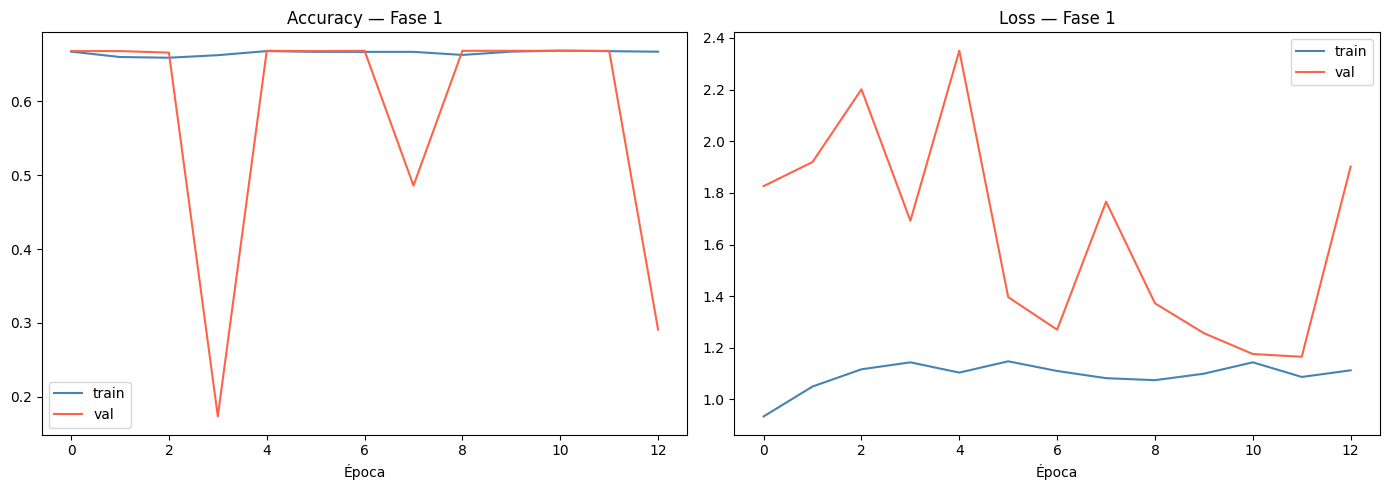

In [ ]:
# Curvas Fase 1
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history1.history['accuracy'],     label='train', color='steelblue')
ax1.plot(history1.history['val_accuracy'], label='val',   color='tomato')
ax1.set_title('Accuracy — Fase 1'); ax1.set_xlabel('Época'); ax1.legend()

ax2.plot(history1.history['loss'],     label='train', color='steelblue')
ax2.plot(history1.history['val_loss'], label='val',   color='tomato')
ax2.set_title('Loss — Fase 1'); ax2.set_xlabel('Época'); ax2.legend()

plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'v3_fase1_curvas.png'), dpi=150)
plt.show()

## 8 · Fase 2a — Fine-tuning gradual (últimas 50 capas)

Primera etapa del fine-tuning: descongelamos las últimas 50 capas con `lr=1e-5`.
Usamos **Focal Loss** aquí porque el clasificador ya está estable.

In [ ]:
# Cargar mejor modelo de Fase 1
model = tf.keras.models.load_model(
    os.path.join(MODELS_DIR, 'densenet201_v3_phase1_best.keras'),
    custom_objects={'FocalLoss': FocalLoss}
)
base_model = model.get_layer('densenet201')

# Descongelar últimas 50 capas
base_model.trainable = True
total_layers = len(base_model.layers)
freeze_until = total_layers - UNFREEZE_PHASE2A
for i, layer in enumerate(base_model.layers):
    layer.trainable = (i >= freeze_until)

trainable_now = sum(1 for l in base_model.layers if l.trainable)
print(f'Capas DenseNet: {total_layers} total, {trainable_now} entrenables (últimas {UNFREEZE_PHASE2A})')

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_PHASE2A),
    loss=focal_loss_fn,
    metrics=['accuracy']
)

callbacks_2a = [
    ModelCheckpoint(
        filepath=os.path.join(MODELS_DIR, 'densenet201_v3_phase2a_best.keras'),
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-7, verbose=1),
    EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True, verbose=1),
]

print('\nCompiado para Fase 2a:')
print(f'  Loss     : FocalLoss(gamma=2)')
print(f'  Optimizer: Adam, lr={LR_PHASE2A}')
print(f'  Épocas   : {EPOCHS_PHASE2A}')

Capas DenseNet: 707 total, 50 entrenables (últimas 50)

Compiado para Fase 2a:
  Loss     : FocalLoss(gamma=2)
  Optimizer: Adam, lr=1e-05
  Épocas   : 20


In [ ]:
print('=' * 60)
print('FASE 2a — Fine-tuning (últimas 50 capas descongeladas)')
print('=' * 60)

history2a = model.fit(
    train_ds,
    epochs=EPOCHS_PHASE2A,
    validation_data=val_ds,
    callbacks=callbacks_2a,
    verbose=1
)

best_val_acc_2a = max(history2a.history['val_accuracy'])
print(f'\nMejor val_accuracy Fase 2a: {best_val_acc_2a:.4f} ({best_val_acc_2a*100:.2f}%)')

FASE 2a — Fine-tuning (últimas 50 capas descongeladas)
Epoch 1/20
    300/Unknown 117s 277ms/step - accuracy: 0.5412 - loss: 0.5514
Epoch 1: val_accuracy improved from None to 0.66854, saving model to /content/drive/MyDrive/skin-cancer-APPR/models/densenet201_v3_phase2a_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/skin-cancer-APPR/models/densenet201_v3_phase2a_best.keras
300/300 ━━━━━━━━━━━━━━━━━━━━ 147s 376ms/step - accuracy: 0.6681 - loss: 0.2771 - val_accuracy: 0.6685 - val_loss: 0.5054 - learning_rate: 1.0000e-05
Epoch 2/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 272ms/step - accuracy: 0.5390 - loss: 0.5030
Epoch 2: val_accuracy did not improve from 0.66854
300/300 ━━━━━━━━━━━━━━━━━━━━ 106s 335ms/step - accuracy: 0.6670 - loss: 0.2548 - val_accuracy: 0.6685 - val_loss: 0.5043 - learning_rate: 1.0000e-05
Epoch 3/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 274ms/step - accuracy: 0.5405 - loss: 0.4457
Epoch 3: val_accuracy did not improve from 0.66854
300/300 ━━━━━━━━━━━━━━━━━━

## 9 · Fase 2b — Fine-tuning profundo (últimas 100 capas)

Segunda etapa: ampliamos a 100 capas descongeladas con `lr=5e-6` (más conservador).
Se parte del mejor modelo de Fase 2a.

In [ ]:
# Cargar mejor modelo de Fase 2a
model = tf.keras.models.load_model(
    os.path.join(MODELS_DIR, 'densenet201_v3_phase2a_best.keras'),
    custom_objects={'FocalLoss': FocalLoss}
)
base_model = model.get_layer('densenet201')

# Descongelar últimas 100 capas
base_model.trainable = True
total_layers = len(base_model.layers)
freeze_until = total_layers - UNFREEZE_PHASE2B
for i, layer in enumerate(base_model.layers):
    layer.trainable = (i >= freeze_until)

trainable_now = sum(1 for l in base_model.layers if l.trainable)
print(f'Capas DenseNet: {total_layers} total, {trainable_now} entrenables (últimas {UNFREEZE_PHASE2B})')

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_PHASE2B),
    loss=focal_loss_fn,
    metrics=['accuracy']
)

callbacks_2b = [
    ModelCheckpoint(
        filepath=os.path.join(MODELS_DIR, 'densenet201_v3_phase2b_best.keras'),
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-8, verbose=1),
    EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True, verbose=1),
]

print('\nCompilado para Fase 2b:')
print(f'  Loss     : FocalLoss(gamma=2)')
print(f'  Optimizer: Adam, lr={LR_PHASE2B}')
print(f'  Épocas   : {EPOCHS_PHASE2B}')

Capas DenseNet: 707 total, 100 entrenables (últimas 100)

Compilado para Fase 2b:
  Loss     : FocalLoss(gamma=2)
  Optimizer: Adam, lr=5e-06
  Épocas   : 20


In [ ]:
print('=' * 60)
print('FASE 2b — Fine-tuning profundo (últimas 100 capas descongeladas)')
print('=' * 60)

history2b = model.fit(
    train_ds,
    epochs=EPOCHS_PHASE2B,
    validation_data=val_ds,
    callbacks=callbacks_2b,
    verbose=1
)

best_val_acc_2b = max(history2b.history['val_accuracy'])
print(f'\nMejor val_accuracy Fase 2b: {best_val_acc_2b:.4f} ({best_val_acc_2b*100:.2f}%)')

FASE 2b — Fine-tuning profundo (últimas 100 capas descongeladas)
Epoch 1/20
    300/Unknown 131s 305ms/step - accuracy: 0.5368 - loss: 0.5138
Epoch 1: val_accuracy improved from None to 0.66854, saving model to /content/drive/MyDrive/skin-cancer-APPR/models/densenet201_v3_phase2b_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/skin-cancer-APPR/models/densenet201_v3_phase2b_best.keras
300/300 ━━━━━━━━━━━━━━━━━━━━ 161s 408ms/step - accuracy: 0.6659 - loss: 0.2603 - val_accuracy: 0.6685 - val_loss: 0.5075 - learning_rate: 5.0000e-06
Epoch 2/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 302ms/step - accuracy: 0.5388 - loss: 0.4685
Epoch 2: val_accuracy did not improve from 0.66854
300/300 ━━━━━━━━━━━━━━━━━━━━ 116s 365ms/step - accuracy: 0.6651 - loss: 0.2377 - val_accuracy: 0.6685 - val_loss: 0.5098 - learning_rate: 5.0000e-06
Epoch 3/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 304ms/step - accuracy: 0.5366 - loss: 0.4242
Epoch 3: val_accuracy did not improve from 0.66854
300/300 ━━━━━━━━

## 10 · Curvas de entrenamiento combinadas

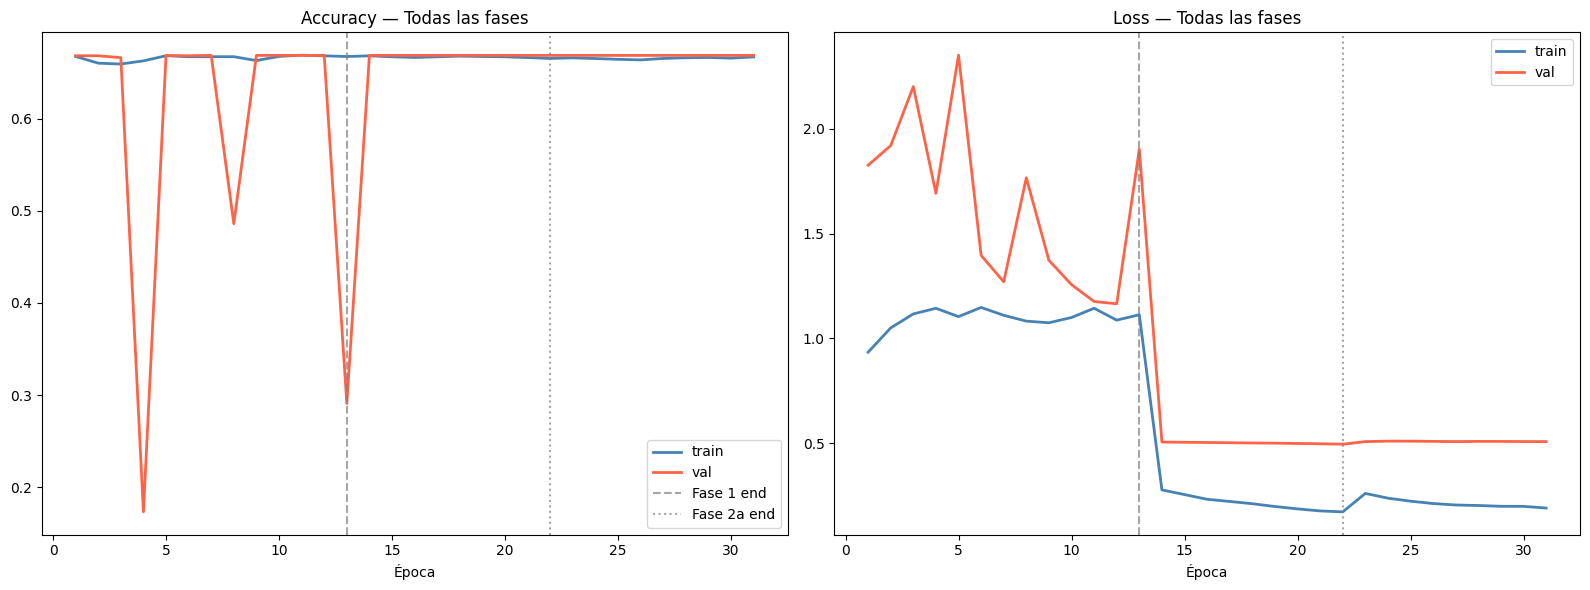

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Concatenar historiales
acc_all  = (history1.history['accuracy'] +
            history2a.history['accuracy'] +
            history2b.history['accuracy'])
vacc_all = (history1.history['val_accuracy'] +
            history2a.history['val_accuracy'] +
            history2b.history['val_accuracy'])
loss_all  = (history1.history['loss'] +
             history2a.history['loss'] +
             history2b.history['loss'])
vloss_all = (history1.history['val_loss'] +
             history2a.history['val_loss'] +
             history2b.history['val_loss'])

ep = range(1, len(acc_all) + 1)
ep1_end  = len(history1.history['accuracy'])
ep2a_end = ep1_end + len(history2a.history['accuracy'])

ax1.plot(ep, acc_all,  label='train', color='steelblue', linewidth=2)
ax1.plot(ep, vacc_all, label='val',   color='tomato',    linewidth=2)
ax1.axvline(ep1_end,  color='gray', linestyle='--', alpha=0.7, label='Fase 1 end')
ax1.axvline(ep2a_end, color='gray', linestyle=':',  alpha=0.7, label='Fase 2a end')
ax1.set_title('Accuracy — Todas las fases'); ax1.legend(); ax1.set_xlabel('Época')

ax2.plot(ep, loss_all,  label='train', color='steelblue', linewidth=2)
ax2.plot(ep, vloss_all, label='val',   color='tomato',    linewidth=2)
ax2.axvline(ep1_end,  color='gray', linestyle='--', alpha=0.7)
ax2.axvline(ep2a_end, color='gray', linestyle=':',  alpha=0.7)
ax2.set_title('Loss — Todas las fases'); ax2.legend(); ax2.set_xlabel('Época')

plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'v3_curvas_completas.png'), dpi=150)
plt.show()

## 11 · Evaluación en conjunto de test

Cargamos el mejor modelo final (Fase 2b) y evaluamos en el test set.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
import seaborn as sns

best_model = tf.keras.models.load_model(
    os.path.join(MODELS_DIR, 'densenet201_v3_phase2b_best.keras'),
    custom_objects={'FocalLoss': FocalLoss}
)

y_pred_probs = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = y_test

print('\nReporte de clasificación:')
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

41/41 ━━━━━━━━━━━━━━━━━━━━ 28s 506ms/step

Reporte de clasificación:
              precision    recall  f1-score   support

       akiec       0.00      0.00      0.00        42
         bcc       0.00      0.00      0.00        67
         bkl       0.00      0.00      0.00       142
          df       0.00      0.00      0.00        14
         mel       0.00      0.00      0.00       144
          nv       0.67      1.00      0.80       858
        vasc       0.00      0.00      0.00        18

    accuracy                           0.67      1285
   macro avg       0.10      0.14      0.11      1285
weighted avg       0.45      0.67      0.53      1285



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


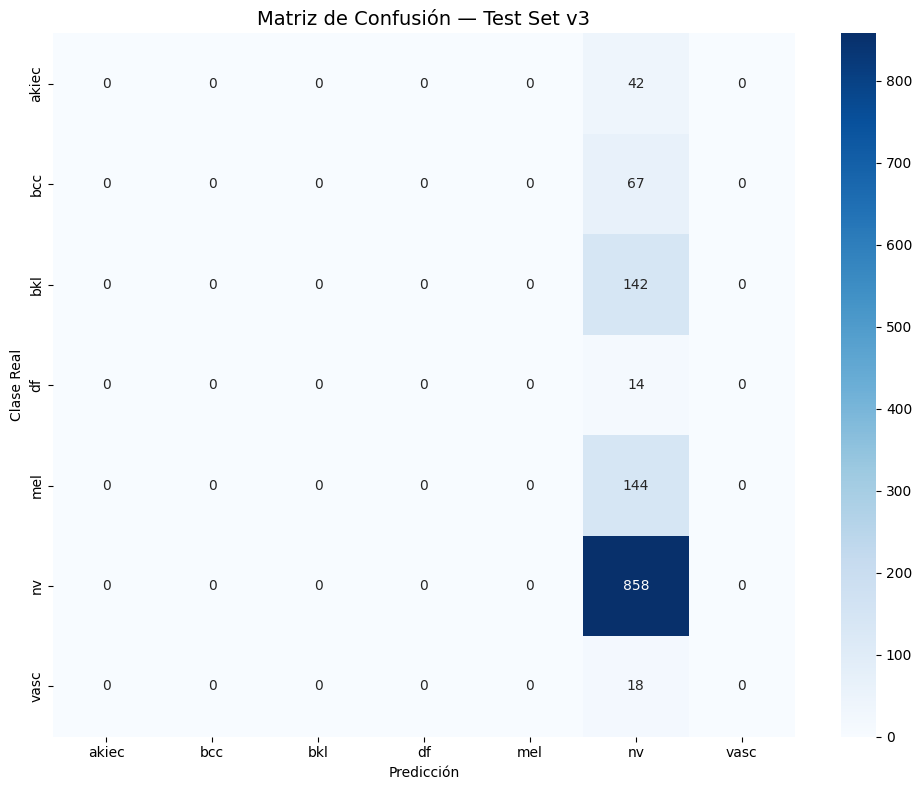

In [ ]:
# Matriz de confusión
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cmap='Blues')
plt.title('Matriz de Confusión — Test Set v3', fontsize=14)
plt.ylabel('Clase Real'); plt.xlabel('Predicción')
plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'v3_confusion_matrix.png'), dpi=150)
plt.show()

## 12 · Resumen de resultados

In [ ]:
acc  = accuracy_score(y_true, y_pred)
f1   = f1_score(y_true, y_pred, average='macro')

print('=' * 50)
print('RESULTADOS FINALES — v3')
print('=' * 50)
print(f'  Val Accuracy Fase 1 : {best_val_acc_p1*100:.2f}%')
print(f'  Val Accuracy Fase 2a: {best_val_acc_2a*100:.2f}%')
print(f'  Val Accuracy Fase 2b: {best_val_acc_2b*100:.2f}%')
print(f'  Test Accuracy Final : {acc*100:.2f}%')
print(f'  F1-Score (macro)    : {f1*100:.2f}%')
print('=' * 50)

# Comparativa con versiones anteriores
print('\nComparativa:')
print(f'  v1 (baseline)    : 54.33% test accuracy')
print(f'  v2 (fine-tuning) : 34.35% val accuracy (entrenamiento incompleto)')
print(f'  v3 (este)        : {acc*100:.2f}% test accuracy')

RESULTADOS FINALES — v3
  Val Accuracy Fase 1 : 66.85%
  Val Accuracy Fase 2a: 66.85%
  Val Accuracy Fase 2b: 66.85%
  Test Accuracy Final : 66.77%
  F1-Score (macro)    : 11.44%

Comparativa:
  v1 (baseline)    : 54.33% test accuracy
  v2 (fine-tuning) : 34.35% val accuracy (entrenamiento incompleto)
  v3 (este)        : 66.77% test accuracy
